In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import silhouette_score

In [2]:
df = pd.read_csv('CSV files/advertising.csv')

In [3]:
df.head()

,Unnamed: 0,TV,radio,newspaper,sales
0,1,230.1,37.8,69.2,22.1
1,2,44.5,39.3,45.1,10.4
2,3,17.2,45.9,69.3,9.3
3,4,151.5,41.3,58.5,18.5
4,5,180.8,10.8,58.4,12.9


In [4]:
df.drop(columns=['Unnamed: 0'], inplace=True)

In [5]:
df.head()

,TV,radio,newspaper,sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9


#### Simple Linear Regression

In [6]:
x = df[['TV']]
y = df['sales']

In [7]:
from sklearn.model_selection import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split(x, y, test_size=0.3, random_state=42)

In [8]:
from sklearn.linear_model import LinearRegression
lr = LinearRegression()
lr.fit(X_train, Y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[0.05]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['TV']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,7.239
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [9]:
print('Slope:', lr.coef_, '\nIntercept:', lr.intercept_)

Slope: [0.0464078] 
Intercept: 7.23945983075114


In [10]:
y_pred = lr.predict(X_test)

In [11]:
print('Mean Squared Error:', mean_squared_error(Y_test, y_pred), '\nR2_Score:', r2_score(Y_test, y_pred))

Mean Squared Error: 8.970991242413616 
R2_Score: 0.6714477229302764


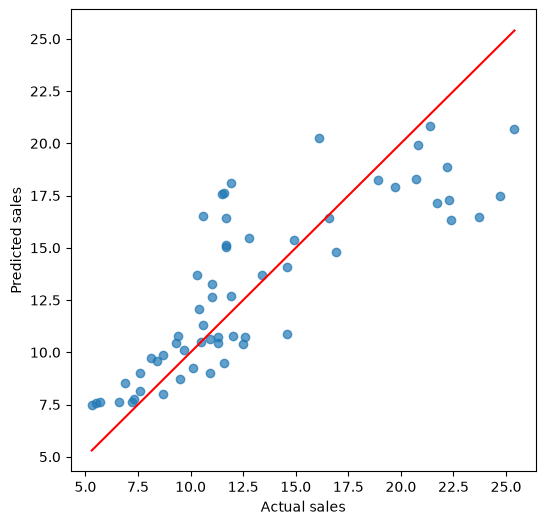

In [12]:
plt.figure(figsize=(6,6))
plt.scatter(Y_test, y_pred, alpha=0.7)
plt.xlabel('Actual sales')
plt.ylabel('Predicted sales')
plt.plot([Y_test.min(), Y_test.max()], [Y_test.min(), Y_test.max()], color='red')
plt.show()

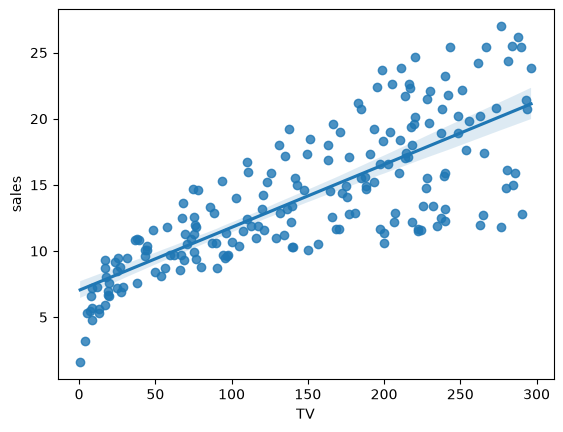

In [13]:
sns.regplot(data=df, x='TV', y='sales')
plt.show()

#### Multivariate Linear Regression

In [14]:
x = df[['TV', 'radio', 'newspaper']]
y = df['sales']

In [15]:
from sklearn.model_selection import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split(x,y,test_size=0.3, random_state=42)

In [16]:
from sklearn.linear_model import LinearRegression
lr = LinearRegression()
lr.fit(X_train, Y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](3,)","[0.04,0.2 ,0.01]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](3,)","['TV','radio','newspaper']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,2.709
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(3)


In [17]:
print('Slope:', lr.coef_, '\nIntercept:', lr.intercept_)

Slope: [0.04405928 0.1992875  0.00688245] 
Intercept: 2.70894909251591


In [18]:
y_pred = lr.predict(X_test)

In [19]:
print('Mean Squared Error:', mean_squared_error(Y_test, y_pred), '\nR2_Score:', r2_score(Y_test, y_pred))

Mean Squared Error: 3.796797236715221 
R2_Score: 0.8609466508230368


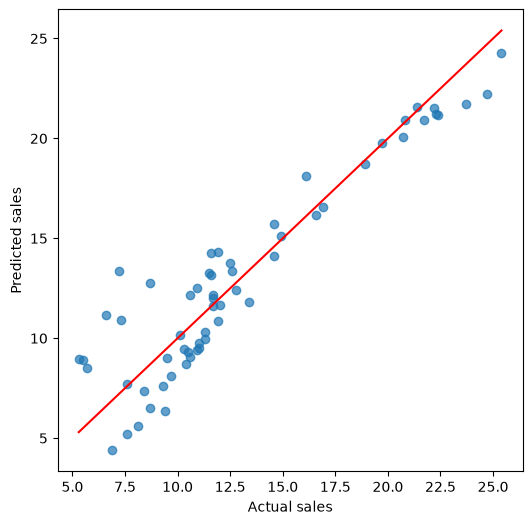

In [20]:
plt.figure(figsize=(6,6))
plt.scatter(Y_test, y_pred,alpha=0.7)
plt.xlabel("Actual sales")
plt.ylabel("Predicted sales")
plt.plot([Y_test.min(), Y_test.max()],[Y_test.min(), Y_test.max()],color='red')
plt.show()


In [21]:
x = df[['TV', 'radio']]
y = df['sales']

In [22]:
from sklearn.model_selection import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split(x, y, test_size=0.3, random_state=42)

In [23]:
from sklearn.linear_model import LinearRegression
lr = LinearRegression()

In [24]:
lr.fit(X_train, Y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](2,)","[0.04,0.2 ]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](2,)","['TV','radio']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,2.838
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,2
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(2)


In [25]:
print('Slope:', lr.coef_, '\nIntercept:', lr.intercept_)

Slope: [0.04407736 0.20260566] 
Intercept: 2.8376172369051798


In [26]:
y_pred = lr.predict(X_test)

In [27]:
print('Mean Squared Error:', mean_squared_error(Y_test, y_pred), '\nR2_Score:', r2_score(Y_test, y_pred))

Mean Squared Error: 3.6690470545306813 
R2_Score: 0.8656253548947074


In [28]:
df1 = pd.DataFrame({'Actual sales' : Y_test, 'Predicted sales' : y_pred})
df1['Residual'] = df1.eval('`Actual sales` - `Predicted sales`')
df1.head()

,Actual sales,Predicted sales,Residual
95,16.9,16.437790,0.462210
15,22.4,21.114624,1.285376
30,21.4,21.481617,-0.081617
158,7.3,10.829471,-3.529471
128,24.7,22.475538,2.224462


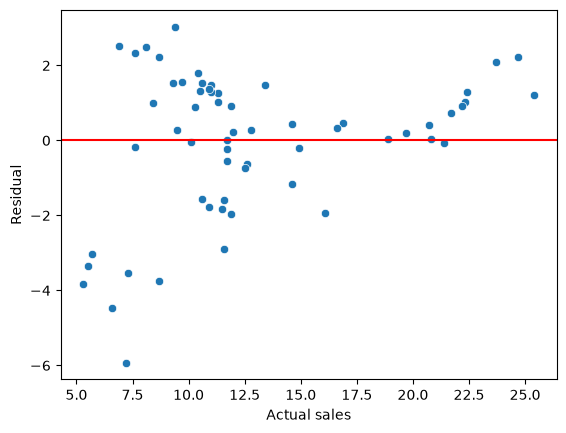

In [29]:
sns.scatterplot(data=df1, x='Actual sales', y='Residual')
plt.axhline(0, color='red')
plt.show()

In [30]:
from sklearn.preprocessing import PolynomialFeatures
poly = PolynomialFeatures()

X_train = poly.fit_transform(X_train)
X_test = poly.transform(X_test)
lr.fit(X_train, Y_train)

y_pred = lr.predict(X_test)

df1 = pd.DataFrame({'Actual sales' : Y_test, 'Predicted sales' : y_pred})
df1['Residual'] = df1['Actual sales'] - df1['Predicted sales']
df1['Residual^2'] = df1['Residual'].apply(lambda x : x**2)
df1.head()

,Actual sales,Predicted sales,Residual,Residual^2
95,16.9,17.126133,-0.226133,0.051136
15,22.4,22.705456,-0.305456,0.093303
30,21.4,20.506464,0.893536,0.798407
158,7.3,7.488396,-0.188396,0.035493
128,24.7,24.472158,0.227842,0.051912


In [31]:
print('Mean Squared Error:', mean_squared_error(Y_test, y_pred), '\nR2_Score:', r2_score(Y_test, y_pred))

Mean Squared Error: 0.35322115943388765 
R2_Score: 0.9870636796865283


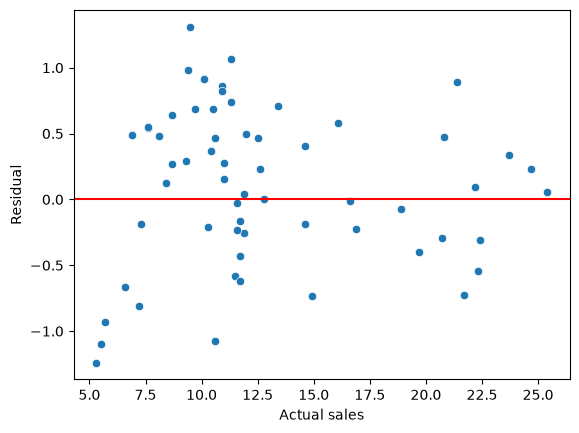

In [32]:
sns.scatterplot(data=df1, x='Actual sales', y='Residual')
plt.axhline(0, color='red')
plt.show()

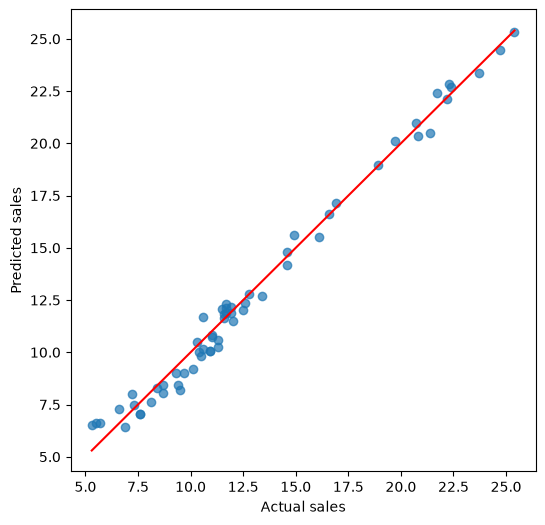

In [33]:
plt.figure(figsize=(6,6))
plt.scatter(Y_test, y_pred, alpha=0.7)
plt.xlabel('Actual sales')
plt.ylabel('Predicted sales')
plt.plot([Y_test.min(), Y_test.max()], [Y_test.min(), Y_test.max()], color='red')
plt.show()

#### Logistic Regression

In [34]:
df = pd.read_csv('CSV files/insurance.csv')
df.head()

,age,sex,bmi,children,smoker,region,charges,insuranceclaim
0,19,0,27.900,0,1,3,16884.92400,1
1,18,1,33.770,1,0,2,1725.55230,1
2,28,1,33.000,3,0,2,4449.46200,0
3,33,1,22.705,0,0,1,21984.47061,0
4,32,1,28.880,0,0,1,3866.85520,1


In [35]:
x = df.iloc[:,:7]
y = df.iloc[:, -1]

In [36]:
from sklearn.model_selection import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split(x, y, test_size=0.3, random_state=42, stratify=y)

In [37]:
from sklearn.preprocessing import StandardScaler
ss = StandardScaler()

X_train = ss.fit_transform(X_train)
X_test = ss.transform(X_test)

In [38]:
from sklearn.linear_model import LogisticRegression
lr = LogisticRegression()

In [39]:
def create_model(obj, X_train, X_test, Y_train, Y_test):
    obj.fit(X_train, Y_train)
    y_pred = obj.predict(X_test)
    print(classification_report(Y_test, y_pred))
    print(confusion_matrix(Y_test, y_pred))

In [40]:
create_model(lr, X_train, X_test, Y_train, Y_test)

              precision    recall  f1-score   support

           0       0.86      0.84      0.85       167
           1       0.89      0.90      0.90       235

    accuracy                           0.88       402
   macro avg       0.88      0.87      0.87       402
weighted avg       0.88      0.88      0.88       402

[[141  26]
 [ 23 212]]


In [41]:
df = pd.read_csv('CSV files/salary.csv')

In [42]:
df.head()

,Unnamed: 0,age,Workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,Income
0,0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,0
1,1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,0
2,2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,0
3,3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,0
4,4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,0


In [43]:
df.drop(columns=['Unnamed: 0', 'fnlwgt', 'education-num', 'race'], inplace=True)

In [44]:
df.head()

,age,Workclass,education,marital-status,occupation,relationship,sex,capital-gain,capital-loss,hours-per-week,native-country,Income
0,39,State-gov,Bachelors,Never-married,Adm-clerical,Not-in-family,Male,2174,0,40,United-States,0
1,50,Self-emp-not-inc,Bachelors,Married-civ-spouse,Exec-managerial,Husband,Male,0,0,13,United-States,0
2,38,Private,HS-grad,Divorced,Handlers-cleaners,Not-in-family,Male,0,0,40,United-States,0
3,53,Private,11th,Married-civ-spouse,Handlers-cleaners,Husband,Male,0,0,40,United-States,0
4,28,Private,Bachelors,Married-civ-spouse,Prof-specialty,Wife,Female,0,0,40,Cuba,0


In [45]:
df_cat = df.select_dtypes('object')
df_num = df.select_dtypes('int64')

In [46]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()

In [47]:
cols = df_cat.columns
for col in cols:
    df_cat[col] = le.fit_transform(df_cat[col])
df_cat

,Workclass,education,marital-status,occupation,relationship,sex,native-country
0,5,9,4,0,1,1,28
1,4,9,2,3,0,1,28
2,2,11,0,5,1,1,28
3,2,1,2,5,0,1,28
4,2,9,2,9,5,0,4
...,...,...,...,...,...,...,...
1027,2,11,0,5,3,0,28
1028,2,15,2,2,0,1,28
1029,2,11,2,13,0,1,28
1030,1,9,2,9,5,0,28


In [48]:
df_new = pd.concat([df_cat, df_num], axis=1)
df_new.head()

,Workclass,education,marital-status,occupation,relationship,sex,native-country,age,capital-gain,capital-loss,hours-per-week,Income
0,5,9,4,0,1,1,28,39,2174,0,40,0
1,4,9,2,3,0,1,28,50,0,0,13,0
2,2,11,0,5,1,1,28,38,0,0,40,0
3,2,1,2,5,0,1,28,53,0,0,40,0
4,2,9,2,9,5,0,4,28,0,0,40,0


In [49]:
x = df_new.drop(columns=['Income'])
y = df_new['Income']

In [50]:
from sklearn.model_selection import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split(x,y, test_size=0.3, random_state=42)

In [51]:
from sklearn.preprocessing import StandardScaler
ss=StandardScaler()

X_train=ss.fit_transform(X_train)
X_test=ss.transform(X_test)

In [52]:
from sklearn.linear_model import LogisticRegression
lr = LogisticRegression()
create_model(lr, X_train, X_test, Y_train, Y_test)

              precision    recall  f1-score   support

           0       0.85      0.94      0.89       240
           1       0.67      0.41      0.51        70

    accuracy                           0.82       310
   macro avg       0.76      0.68      0.70       310
weighted avg       0.81      0.82      0.81       310

[[226  14]
 [ 41  29]]


In [53]:
from imblearn.over_sampling import RandomOverSampler
ros = RandomOverSampler()
X_train, Y_train = ros.fit_resample(X_train, Y_train)

In [54]:
create_model(lr, X_train, X_test, Y_train, Y_test)

              precision    recall  f1-score   support

           0       0.91      0.71      0.80       240
           1       0.43      0.76      0.55        70

    accuracy                           0.72       310
   macro avg       0.67      0.73      0.68       310
weighted avg       0.80      0.72      0.74       310

[[171  69]
 [ 17  53]]


In [55]:
df=pd.read_csv("CSV files/user_data.csv")

In [56]:
df.head()

,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0


In [57]:
df.drop(columns=['User ID'], inplace=True)
df['Gender'] = df['Gender'].map({'Male' : 0, 'Female' : 1})

In [58]:
df.head()

,Gender,Age,EstimatedSalary,Purchased
0,0,19,19000,0
1,0,35,20000,0
2,1,26,43000,0
3,1,27,57000,0
4,0,19,76000,0


In [59]:
x=df.drop(columns=['Purchased'])
y=df['Purchased']

In [60]:
from sklearn.model_selection import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split(x,y, test_size=0.3, random_state=42)

In [61]:
from sklearn.preprocessing import StandardScaler
ss=StandardScaler()
X_train=ss.fit_transform(X_train)
X_test=ss.transform(X_test)

In [62]:
from sklearn.linear_model import LogisticRegression
lr = LogisticRegression()
create_model(lr, X_train, X_test, Y_train, Y_test)

              precision    recall  f1-score   support

           0       0.83      0.97      0.89        73
           1       0.94      0.68      0.79        47

    accuracy                           0.86       120
   macro avg       0.88      0.83      0.84       120
weighted avg       0.87      0.86      0.85       120

[[71  2]
 [15 32]]


In [63]:
from imblearn.over_sampling import RandomOverSampler
ros = RandomOverSampler()
X_train, Y_train = ros.fit_resample(X_train, Y_train)

In [64]:
create_model(lr, X_train, X_test, Y_train, Y_test)

              precision    recall  f1-score   support

           0       0.92      0.89      0.90        73
           1       0.84      0.87      0.85        47

    accuracy                           0.88       120
   macro avg       0.88      0.88      0.88       120
weighted avg       0.88      0.88      0.88       120

[[65  8]
 [ 6 41]]


#### K Nearest Neighbors

In [65]:
from sklearn.neighbors import KNeighborsClassifier
knn=KNeighborsClassifier(n_neighbors=5, metric='minkowski', p=2)
create_model(knn, X_train, X_test, Y_train, Y_test)

              precision    recall  f1-score   support

           0       0.94      0.92      0.93        73
           1       0.88      0.91      0.90        47

    accuracy                           0.92       120
   macro avg       0.91      0.92      0.91       120
weighted avg       0.92      0.92      0.92       120

[[67  6]
 [ 4 43]]


In [66]:
df = pd.read_csv("CSV files/bank.csv")

In [67]:
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,0,1,1,0,2343,1,0,2,5,8,1042,1,-1,0,3,1
1,56,0,1,1,0,45,0,0,2,5,8,1467,1,-1,0,3,1
2,41,9,1,1,0,1270,1,0,2,5,8,1389,1,-1,0,3,1
3,55,7,1,1,0,2476,1,0,2,5,8,579,1,-1,0,3,1
4,54,0,1,2,0,184,0,0,2,5,8,673,2,-1,0,3,1


In [68]:
x= df.drop(columns=['deposit'])
y= df['deposit']

In [69]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x,y, test_size=0.3, random_state=42)

In [70]:
from sklearn.preprocessing import StandardScaler
ss=StandardScaler()
x_train=ss.fit_transform(x_train)
x_test=ss.transform(x_test)

In [71]:
from sklearn.linear_model import LogisticRegression
lr = LogisticRegression()
create_model(lr, X_train, X_test, Y_train, Y_test)

              precision    recall  f1-score   support

           0       0.92      0.89      0.90        73
           1       0.84      0.87      0.85        47

    accuracy                           0.88       120
   macro avg       0.88      0.88      0.88       120
weighted avg       0.88      0.88      0.88       120

[[65  8]
 [ 6 41]]


In [72]:
from sklearn.neighbors import KNeighborsClassifier
knn=KNeighborsClassifier(n_neighbors=5, metric='minkowski', p=2)
create_model(knn, X_train, X_test, Y_train, Y_test)

              precision    recall  f1-score   support

           0       0.94      0.92      0.93        73
           1       0.88      0.91      0.90        47

    accuracy                           0.92       120
   macro avg       0.91      0.92      0.91       120
weighted avg       0.92      0.92      0.92       120

[[67  6]
 [ 4 43]]


#### Support Vector Machine

In [73]:
from sklearn.svm import LinearSVC
svc = LinearSVC(random_state=42)
create_model(svc, X_train, X_test, Y_train, Y_test)

              precision    recall  f1-score   support

           0       0.90      0.89      0.90        73
           1       0.83      0.85      0.84        47

    accuracy                           0.88       120
   macro avg       0.87      0.87      0.87       120
weighted avg       0.88      0.88      0.88       120

[[65  8]
 [ 7 40]]


In [74]:
from sklearn.svm import SVC
svc = SVC(random_state=42, kernel='poly')
create_model(svc, X_train, X_test, Y_train, Y_test)

              precision    recall  f1-score   support

           0       0.95      0.95      0.95        73
           1       0.91      0.91      0.91        47

    accuracy                           0.93       120
   macro avg       0.93      0.93      0.93       120
weighted avg       0.93      0.93      0.93       120

[[69  4]
 [ 4 43]]


In [75]:
from sklearn.svm import SVC
svc = SVC(random_state=42,kernel='rbf')
create_model(svc, X_train, X_test, Y_train, Y_test)

              precision    recall  f1-score   support

           0       0.96      0.90      0.93        73
           1       0.86      0.94      0.90        47

    accuracy                           0.92       120
   macro avg       0.91      0.92      0.91       120
weighted avg       0.92      0.92      0.92       120

[[66  7]
 [ 3 44]]


#### Decision Tree 

In [76]:
df = pd.read_csv('CSV files/salary.csv')

In [77]:
df.head()

,Unnamed: 0,age,Workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,Income
0,0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,0
1,1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,0
2,2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,0
3,3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,0
4,4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,0


In [78]:
df.drop(columns= ['Unnamed: 0', 'fnlwgt', 'education-num', 'race'], inplace=True)

In [79]:
df_cat=df.select_dtypes('object')
df_num=df.select_dtypes('int64')

In [80]:
from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()

In [81]:
cols=df_cat.columns
for col in cols:
    df_cat[col] = le.fit_transform(df_cat[col])
df_cat

,Workclass,education,marital-status,occupation,relationship,sex,native-country
0,5,9,4,0,1,1,28
1,4,9,2,3,0,1,28
2,2,11,0,5,1,1,28
3,2,1,2,5,0,1,28
4,2,9,2,9,5,0,4
...,...,...,...,...,...,...,...
1027,2,11,0,5,3,0,28
1028,2,15,2,2,0,1,28
1029,2,11,2,13,0,1,28
1030,1,9,2,9,5,0,28


In [82]:
df_new = pd.concat([df_cat, df_num], axis=1)
df_new.head()

,Workclass,education,marital-status,occupation,relationship,sex,native-country,age,capital-gain,capital-loss,hours-per-week,Income
0,5,9,4,0,1,1,28,39,2174,0,40,0
1,4,9,2,3,0,1,28,50,0,0,13,0
2,2,11,0,5,1,1,28,38,0,0,40,0
3,2,1,2,5,0,1,28,53,0,0,40,0
4,2,9,2,9,5,0,4,28,0,0,40,0


In [83]:
x = df_new.drop(columns=['Income'])
y = df_new['Income']

In [84]:
from sklearn.model_selection import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split(x, y, test_size=0.3, random_state=42)

In [85]:
from sklearn.tree import DecisionTreeClassifier
dt = DecisionTreeClassifier(max_depth=7, random_state=42)
create_model(dt, X_train, X_test, Y_train, Y_test)

              precision    recall  f1-score   support

           0       0.94      0.82      0.88       240
           1       0.57      0.83      0.67        70

    accuracy                           0.82       310
   macro avg       0.76      0.82      0.77       310
weighted avg       0.86      0.82      0.83       310

[[196  44]
 [ 12  58]]


In [86]:
dict1 = pd.DataFrame({'Input features' : x.columns, 'Information Gain' : dt.feature_importances_})
dict1.sort_values(by='Information Gain', ascending=False)

,Input features,Information Gain
4,relationship,0.398962
8,capital-gain,0.153058
7,age,0.139675
10,hours-per-week,0.106659
1,education,0.104512
0,Workclass,0.026407
9,capital-loss,0.025914
3,occupation,0.016826
6,native-country,0.016099
2,marital-status,0.011888


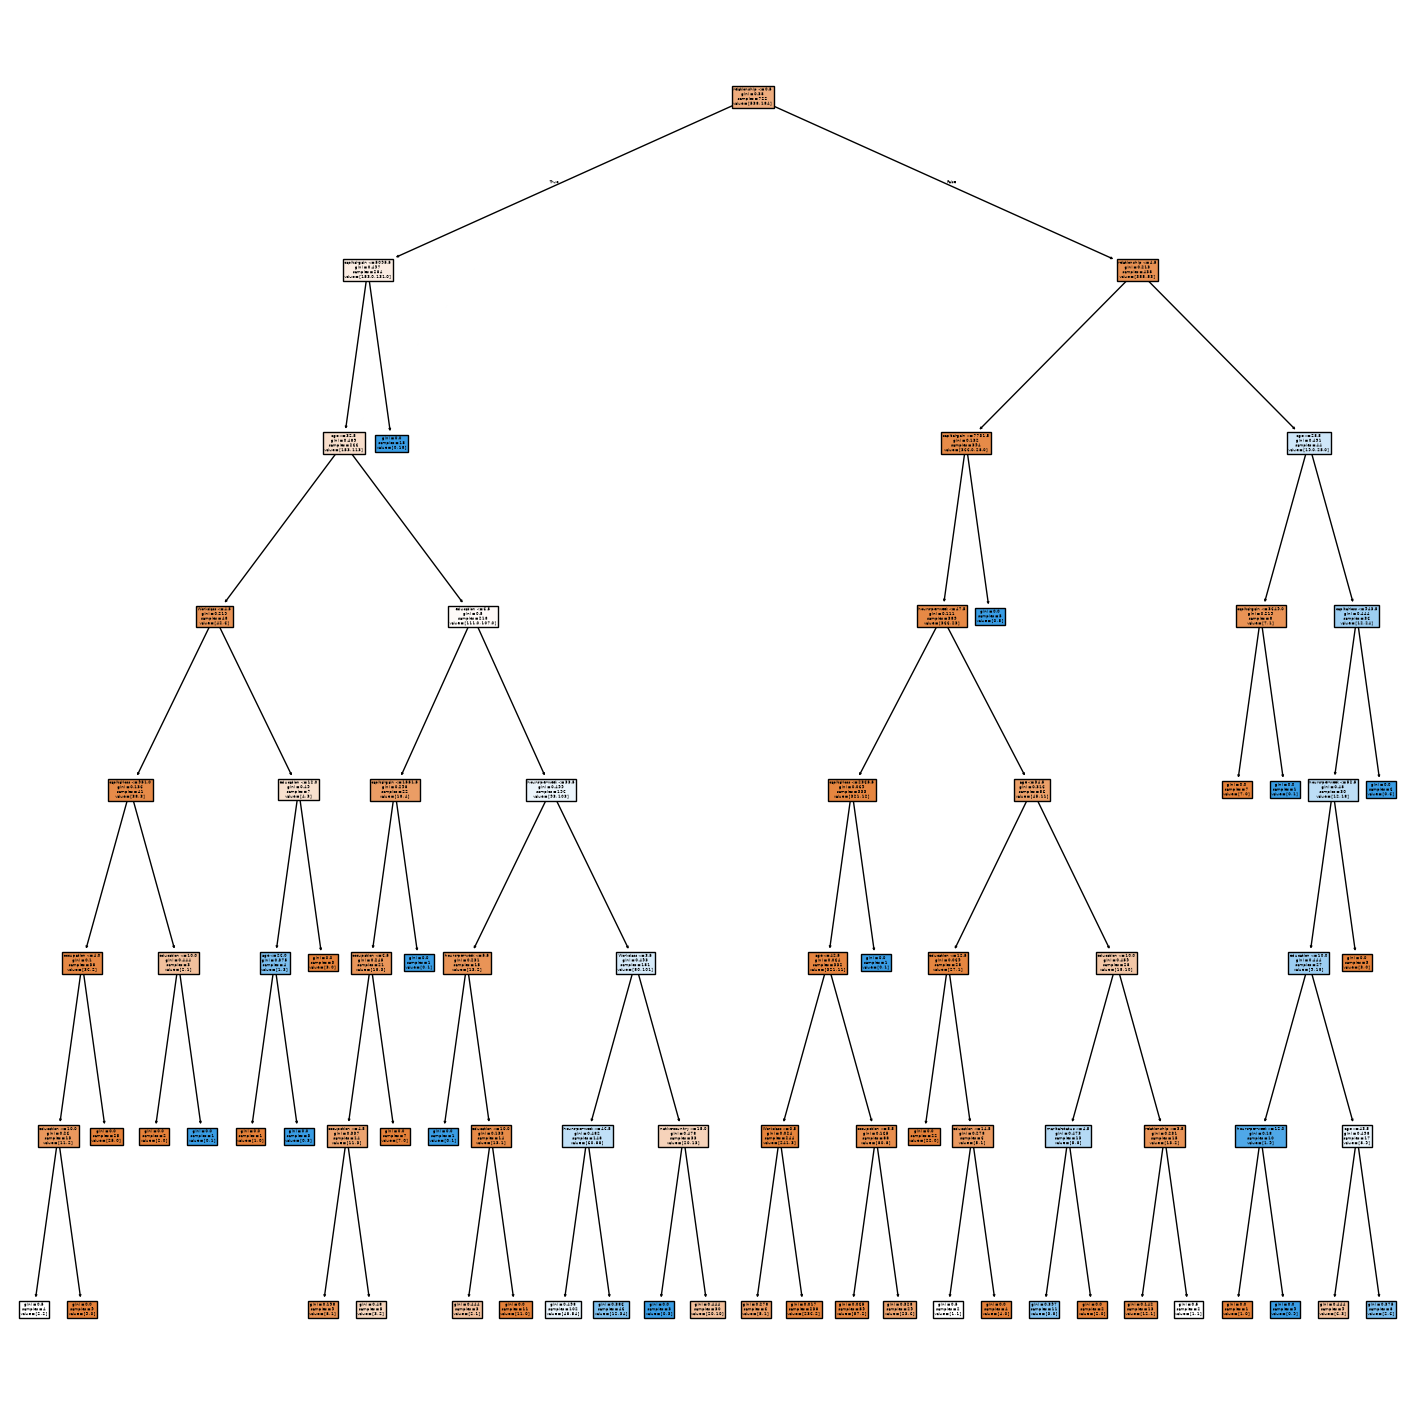

In [87]:
from sklearn import tree
plt.figure(figsize=(18,18))
tree.plot_tree(dt, feature_names=x.columns, filled=True)
plt.show()

In [88]:
from sklearn.tree import DecisionTreeClassifier
dt = DecisionTreeClassifier(min_samples_leaf=45, random_state=42)
create_model(dt, X_train, X_test, Y_train, Y_test)

              precision    recall  f1-score   support

           0       0.85      0.89      0.87       240
           1       0.54      0.46      0.50        70

    accuracy                           0.79       310
   macro avg       0.70      0.67      0.68       310
weighted avg       0.78      0.79      0.78       310

[[213  27]
 [ 38  32]]


In [89]:
dict2 = pd.DataFrame({'Input features' : x.columns, 'Information Gain' : dt.feature_importances_})
dict2.sort_values(by='Information Gain', ascending=False)

,Input features,Information Gain
4,relationship,0.605632
7,age,0.252703
10,hours-per-week,0.107915
3,occupation,0.033750
0,Workclass,0.000000
1,education,0.000000
2,marital-status,0.000000
5,sex,0.000000
6,native-country,0.000000
8,capital-gain,0.000000


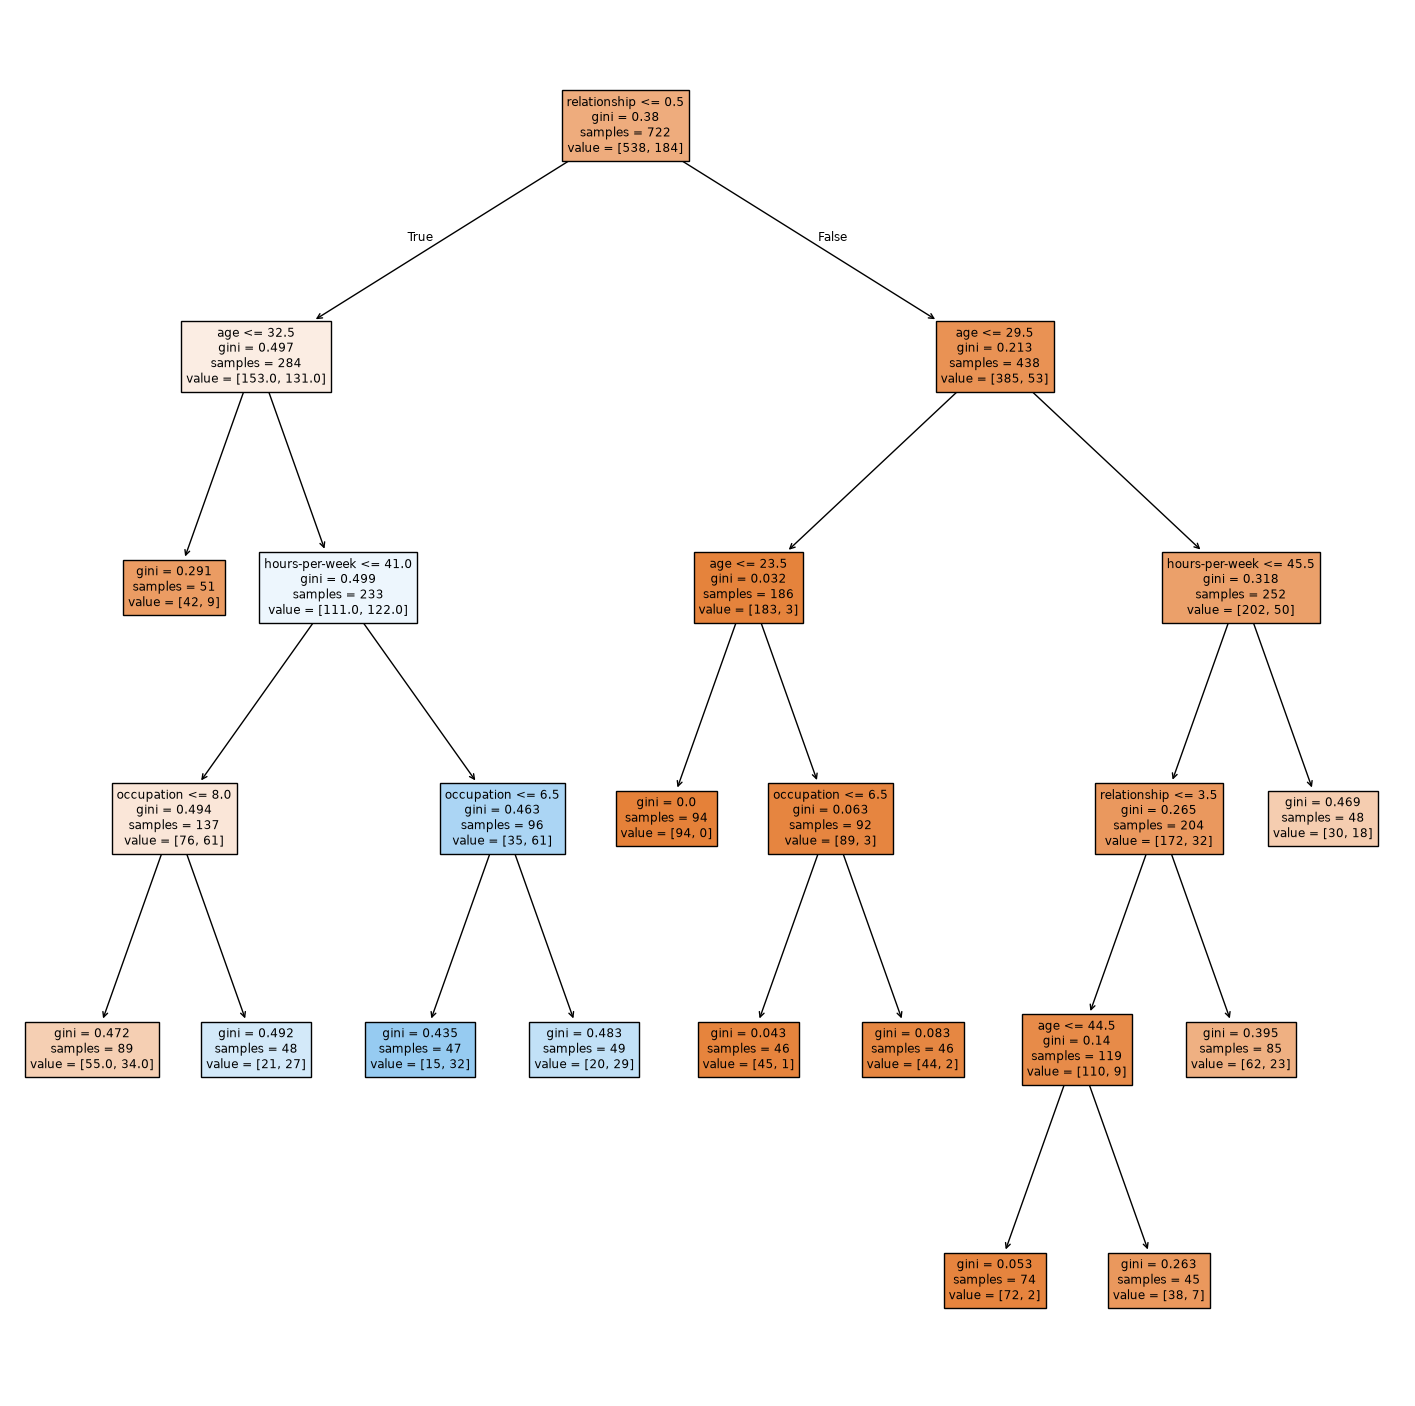

In [90]:
from sklearn import tree
plt.figure(figsize=(18,18))
tree.plot_tree(dt, feature_names=x.columns, filled=True)
plt.show()

#### Ensemble ML Algorithm

In [91]:
heart = pd.read_csv('CSV files/heart.csv')
heart.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [92]:
x = heart.drop(columns=['target'])
y= heart['target']

In [93]:
from sklearn.model_selection import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split(x, y, test_size=0.3, random_state=42)

In [94]:
from sklearn.ensemble import AdaBoostClassifier
abc = AdaBoostClassifier(random_state=42)
create_model(abc, X_train, X_test, Y_train, Y_test)

              precision    recall  f1-score   support

           0       0.76      0.85      0.80        41
           1       0.87      0.78      0.82        50

    accuracy                           0.81        91
   macro avg       0.81      0.82      0.81        91
weighted avg       0.82      0.81      0.81        91

[[35  6]
 [11 39]]


In [95]:
from sklearn.ensemble import GradientBoostingClassifier
gbc = GradientBoostingClassifier(random_state=42)
create_model(gbc, X_train, X_test, Y_train, Y_test)

              precision    recall  f1-score   support

           0       0.73      0.80      0.77        41
           1       0.83      0.76      0.79        50

    accuracy                           0.78        91
   macro avg       0.78      0.78      0.78        91
weighted avg       0.78      0.78      0.78        91

[[33  8]
 [12 38]]


#### Naive Bayes

In [96]:
flower = pd.read_csv('CSV files/iris.csv')
flower.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


In [97]:
x = flower.drop(columns=['species'])
y= flower['species']

In [98]:
from sklearn.model_selection import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split(x,y, test_size=0.3, random_state=42)

In [99]:
from sklearn.naive_bayes import GaussianNB
gnb = GaussianNB()
create_model(gnb, X_train, X_test, Y_train, Y_test)

                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        19
Iris-versicolor       1.00      0.92      0.96        13
 Iris-virginica       0.93      1.00      0.96        13

       accuracy                           0.98        45
      macro avg       0.98      0.97      0.97        45
   weighted avg       0.98      0.98      0.98        45

[[19  0  0]
 [ 0 12  1]
 [ 0  0 13]]


#### KMeans Partitioning Clustering Algorithm

In [100]:
df = pd.read_csv('CSV files/mall.csv')
df.head()

,INCOME,SPEND
0,233,150
1,250,187
2,204,172
3,236,178
4,354,163


In [101]:
X = df[['INCOME', 'SPEND']]

In [102]:
from sklearn.preprocessing import StandardScaler
ss = StandardScaler()
X = ss.fit_transform(X)

In [103]:
from sklearn.cluster import KMeans
kmeans = KMeans(n_clusters=3, random_state=42)
clusters = kmeans.fit_predict(X)
print("Silhouette Score:", silhouette_score(X, clusters))

Silhouette Score: 0.37049751282316423


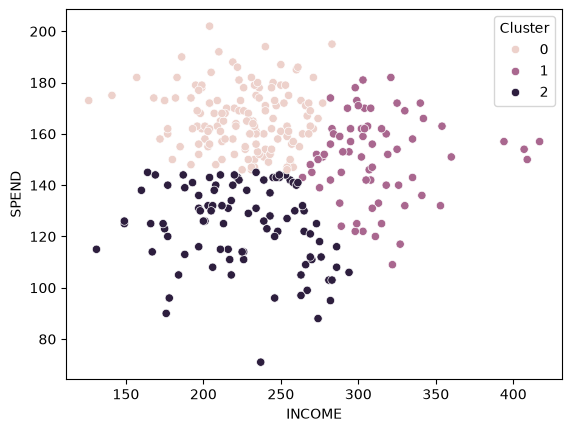

In [104]:
df['Cluster'] = clusters
sns.scatterplot(data = df, x='INCOME', y='SPEND', hue='Cluster')
plt.show()

#### Agglomerative Hierarchical Clustering Algorithm

In [105]:
from sklearn.cluster import AgglomerativeClustering
ag = AgglomerativeClustering(n_clusters=3, linkage='complete')
clusters = ag.fit_predict(X)
print('score:',silhouette_score(X,clusters))

score: 0.2535811308915289


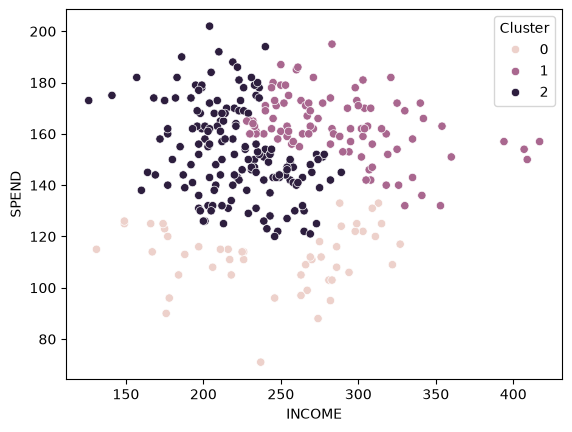

In [106]:
df['Cluster'] = clusters
sns.scatterplot(data = df, x='INCOME', y='SPEND', hue='Cluster')
plt.show()